![Logo SENATI](../static/logo_senati.png)

**SENATI | Escuela de Tecnologías de la Información**  
**Taller: Machine Learning y Deep Learning**  
*Instructor: Ing. Gunar Castro Iñigo*

---

# Estimación del costo de transporte agrícola — caso práctico intermedio 02

**Contexto:** Un transportista quiere estimar el costo de un viaje a partir de la distancia, el peso de la carga y el tipo de vía. Los datos son simulados, inspirados en el transporte agrícola regional.

**Objetivo:** aplicar regresión múltiple desde la lectura de datos hasta una web pequeña con Flask.

## Paso 1. Explorar el CSV
Entradas `X`: `distancia_km`, `carga_kg`, `via_no_asfaltada`. Respuesta `y`: `costo_transporte_soles`.

**Los datos son simulados**, no registros reales.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

datos = pd.read_csv('../caso_02_transporte_agricola/datos.csv', encoding='utf-8-sig')
print(datos.head())
print()
print('Filas y columnas:', datos.shape)
print('Ausentes por columna:')
print(datos.isna().sum())
print('Filas duplicadas:', datos.duplicated().sum())
datos.describe().round(2)

   viaje  distancia_km  carga_kg  via_no_asfaltada  costo_transporte_soles
0  R-001         140.1      1775                 0                  592.32
1  R-002         131.9       425                 1                  442.18
2  R-003         102.8      1525                 0                  478.20
3  R-004          50.5       325                 1                  221.73
4  R-005          67.1       975                 0                  314.59

Filas y columnas: (130, 5)
Ausentes por columna:
viaje                     0
distancia_km              0
carga_kg                  0
via_no_asfaltada          0
costo_transporte_soles    0
dtype: int64
Filas duplicadas: 0


,distancia_km,carga_kg,via_no_asfaltada,costo_transporte_soles
count,130.00,130.00,130.00,130.00
mean,84.52,999.04,0.52,377.97
std,46.70,569.06,0.50,142.02
min,3.00,50.00,0.00,73.30
25%,50.72,537.50,0.00,273.57
50%,88.95,925.00,1.00,386.62
75%,119.85,1475.00,1.00,485.76
max,164.60,2050.00,1.00,690.23


distancia_km              0.902
carga_kg                  0.409
via_no_asfaltada         -0.048
costo_transporte_soles    1.000
Name: costo_transporte_soles, dtype: float64


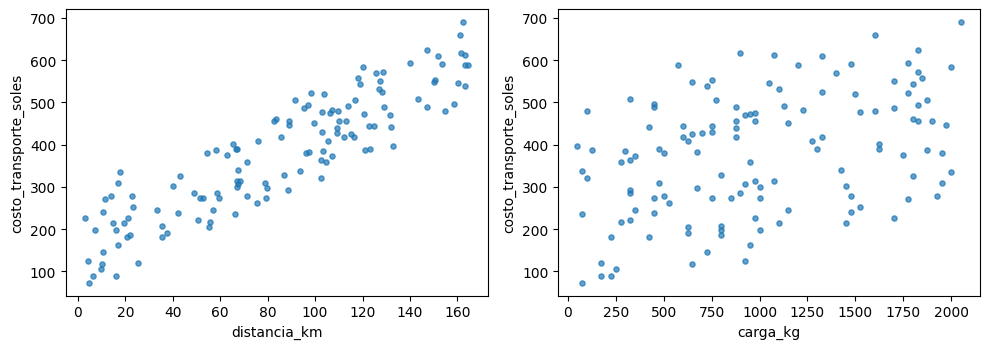

In [2]:
# Relación de cada variable de entrada con la respuesta
columnas = ['distancia_km', 'carga_kg', 'via_no_asfaltada']
objetivo = 'costo_transporte_soles'
print(datos[columnas + [objetivo]].corr()[objetivo].round(3))

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
for eje, col in zip(ejes, columnas[:2]):
    eje.scatter(datos[col], datos[objetivo], s=14, alpha=.7)
    eje.set_xlabel(col); eje.set_ylabel(objetivo)
plt.tight_layout(); plt.show()

**Lectura del gráfico:** las dos variables numéricas muestran una relación creciente con la respuesta, por eso tiene sentido probar una regresión lineal. Las variables 0/1 funcionan como un interruptor que suma o resta un monto fijo.

## Paso 2. Separar y entrenar
Se reserva 20 % de las filas para **probar**; el modelo solo aprende del 80 % restante.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

X = datos[columnas]
y = datos[objetivo]

X_ent, X_prueba, y_ent, y_prueba = train_test_split(X, y, test_size=0.2, random_state=42)
print('Entrenamiento:', len(X_ent), 'filas | Prueba:', len(X_prueba), 'filas')

modelo = LinearRegression()
modelo.fit(X_ent, y_ent)

print('Intercepto:', round(modelo.intercept_, 4))
for nombre, coef in zip(columnas, modelo.coef_):
    print(f'  {nombre}: {coef:.4f}')

Entrenamiento: 104 filas | Prueba: 26 filas
Intercepto: 21.5196
  distancia_km: 2.7742
  carga_kg: 0.1073
  via_no_asfaltada: 26.4419


**Interpretación de los coeficientes:** cada kilómetro suma ≈ S/ 2.77; cada kg suma ≈ S/ 0.107 (≈ S/ 10.7 por cada 100 kg); una vía no asfaltada suma ≈ S/ 26.4. El intercepto (≈ S/ 21.5) es el costo base.

## Paso 3. Evaluar con los datos de prueba

MAE = 17.794
R²  = 0.977
Error promedio relativo ≈ 4.7 % del valor promedio (378.0)


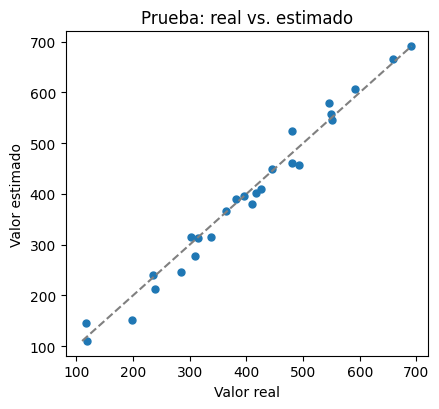

In [4]:
pred = modelo.predict(X_prueba)
mae = mean_absolute_error(y_prueba, pred)
r2 = r2_score(y_prueba, pred)
print(f'MAE = {mae:.3f}')
print(f'R²  = {r2:.3f}')
print(f'Error promedio relativo ≈ {mae / y.mean() * 100:.1f} % del valor promedio ({y.mean():.1f})')

plt.figure(figsize=(4.5, 4.2))
plt.scatter(y_prueba, pred, s=25)
lim = [min(y_prueba.min(), pred.min()), max(y_prueba.max(), pred.max())]
plt.plot(lim, lim, color='gray', linestyle='--')
plt.xlabel('Valor real'); plt.ylabel('Valor estimado'); plt.title('Prueba: real vs. estimado')
plt.tight_layout(); plt.show()

**MAE:** en promedio la estimación se equivoca por ≈ S/ 18 por viaje (≈ 4.7 % del costo promedio de S/ 378).  
**R²:** el modelo explica ≈ 97.7 % de la variación del costo.

## Paso 4. Guardar `modelo.json`
La web leerá estos números; no necesita Scikit-learn en el hosting.

In [5]:
resumen = {
    'caso': 'caso-02',
    'columnas': columnas,
    'objetivo': objetivo,
    'intercepto': float(modelo.intercept_),
    'coeficientes': {c: float(k) for c, k in zip(columnas, modelo.coef_)},
    'mae': float(mae),
    'r2': float(r2),
}
print(json.dumps(resumen, indent=2, ensure_ascii=False))
# Nota: el archivo final modelo.json lo genera entrenar.py (con los mismos números y más datos para la web).

{
  "caso": "caso-02",
  "columnas": [
    "distancia_km",
    "carga_kg",
    "via_no_asfaltada"
  ],
  "objetivo": "costo_transporte_soles",
  "intercepto": 21.51964453823132,
  "coeficientes": {
    "distancia_km": 2.7742350957517043,
    "carga_kg": 0.10728632335623635,
    "via_no_asfaltada": 26.441864153782838
  },
  "mae": 17.793975041858538,
  "r2": 0.977187305382063
}

## Paso 5. Pruebas obligatorias

In [6]:
pruebas = [
    ('Viaje de 25 km, 400 kg, ruta asfaltada', {'distancia_km': 25, 'carga_kg': 400, 'via_no_asfaltada': 0}),
    ('Viaje de 100 km, 1200 kg, ruta no asfaltada', {'distancia_km': 100, 'carga_kg': 1200, 'via_no_asfaltada': 1}),
]
for nombre, valores in pruebas:
    fila = pd.DataFrame([valores])[columnas]
    estimado = max(modelo.predict(fila)[0], 0)
    print(f'{nombre}: {estimado:.2f} soles')

Viaje de 25 km, 400 kg, ruta asfaltada: 133.79 soles
Viaje de 100 km, 1200 kg, ruta no asfaltada: 454.13 soles


**¿Tienen sentido?** Sí: 25 km, 400 kg y ruta asfaltada da ≈ S/ 134 (viaje corto y liviano); 100 km, 1200 kg y ruta no asfaltada da ≈ S/ 454 (viaje largo, pesado y de trocha). Ambos están dentro del rango de los datos (S/ 73 a S/ 690).

**¿Cuándo puede fallar?** Fuera de los rangos (3–165 km, 50–2050 kg), si cambian combustible o peajes, o si el efecto de la vía crece con la distancia; además los datos son simulados.

## Conclusiones
- La regresión lineal múltiple se ajusta bien a estos datos simulados.
- Las métricas se calcularon solo con datos de prueba, que el modelo no vio al entrenar.
- La estimación es una **referencia**, no una garantía: con pocos datos, otra separación cambiaría un poco el MAE y el R².
- La web en Flask valida rangos y muestra una advertencia de estimación.